# 01 — EDA inicial de VOC para segmentación binaria

**Alcance:** primer bloque exploratorio del entregable 1, no EDA final ni evaluación de modelos.
Se trabaja con anotaciones locales de etiquetas de peligro, no con las categorías estándar de Pascal VOC.

Regenerar primero `python scripts/inicio_voc.py` y después `python scripts/crear_cuaderno_inicio.py`.
El segundo comando ejecuta las celdas y conserva sus salidas. Dependencias y pasos en
`INICIO_REPRODUCIBLE.md`. No se modifican originales ni se entrena un modelo.


In [1]:
from pathlib import Path
import csv, json, sys
import numpy as np
from PIL import Image, ImageDraw

# Funciona al abrir desde la raíz del proyecto, notebooks o DEEP LEARNING.
here = Path.cwd()
candidates = [here, *here.parents, here / 'tesis_imo_para_codex']
project = next(p for p in candidates if (p / 'config/inicio_voc.json').exists())
sys.path.insert(0, str(project / 'scripts'))
from graficos_eda import bars, composition, histogram, scatter
out = project / 'resultados/inicio_voc'
# Los JSON guardan la auditoría; el CSV permite analizar cada imagen por separado.
# No se vuelve a inferir una clase a partir del nombre de la fotografía.
summary = json.loads((out / 'resumen.json').read_text(encoding='utf-8'))
run = json.loads((out / 'ejecucion.json').read_text(encoding='utf-8'))
with (out / 'inventario.csv').open(encoding='utf-8-sig', newline='') as f:
    rows = list(csv.DictReader(f))
valid = [r for r in rows if r['status'] == 'ok']
# 'ok' certifica lectura, tamaño y colores; NO la calidad de la anotación.
assert len(valid) == summary['status_counts']['ok']
figures = out / 'graficos'
figures.mkdir(exist_ok=True)
def show(figure, filename):
    # Exportar la misma figura mostrada permite reutilizarla en el informe.
    figure.save(figures / (filename + '.png'))
    display(figure)
print('Firma de imágenes y máscaras:', run['dataset_image_mask_signature'])
print('Versiones:', run['packages'])
print('Semilla de muestra:', run['seed'])


Firma de imágenes y máscaras: df471283f008122596baa85c5c09edcc6255658006d24bbd315d8cf2b49d1675
Versiones: {'numpy': '2.3.5', 'Pillow': '12.3.0'}
Semilla de muestra: 20261106


## 1. Cobertura e integridad

Una fila `ok` no certifica la corrección del dibujo ni de su clase. Los JPG sin máscara
no pueden asumirse como ejemplos negativos. No sumar SegmentationClass, Raw y Object
como si fueran observaciones independientes.


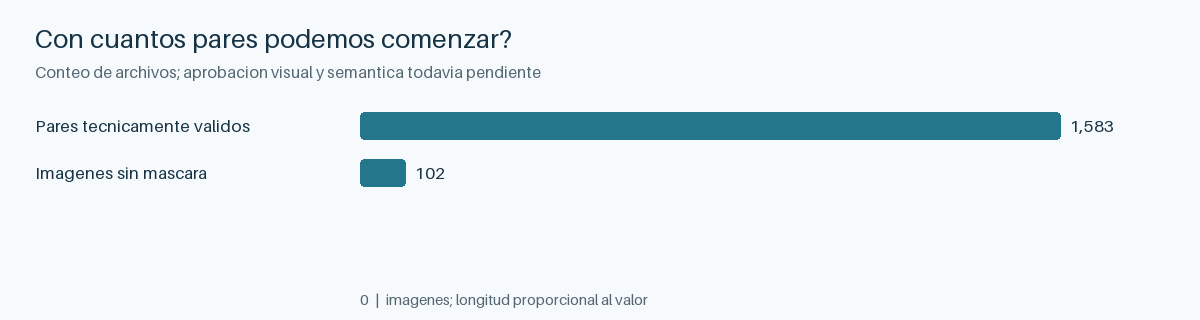

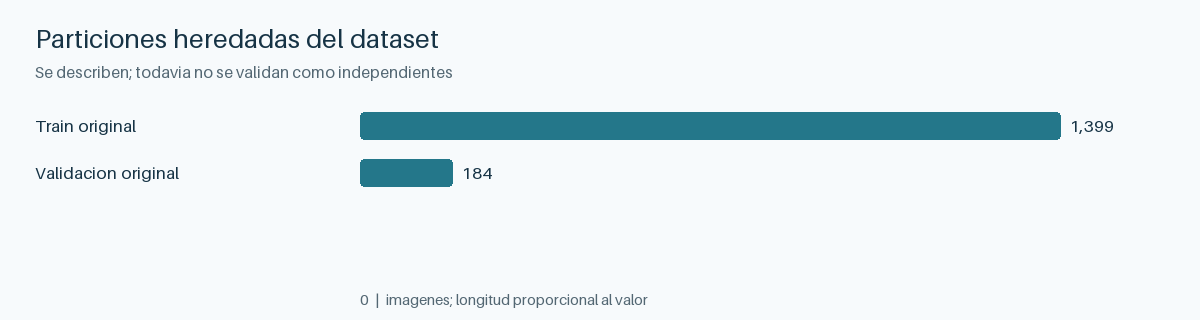

Solapamiento de IDs train/val: 0
IDs de splits sin par: {'train': [], 'val': [], 'trainval': []}


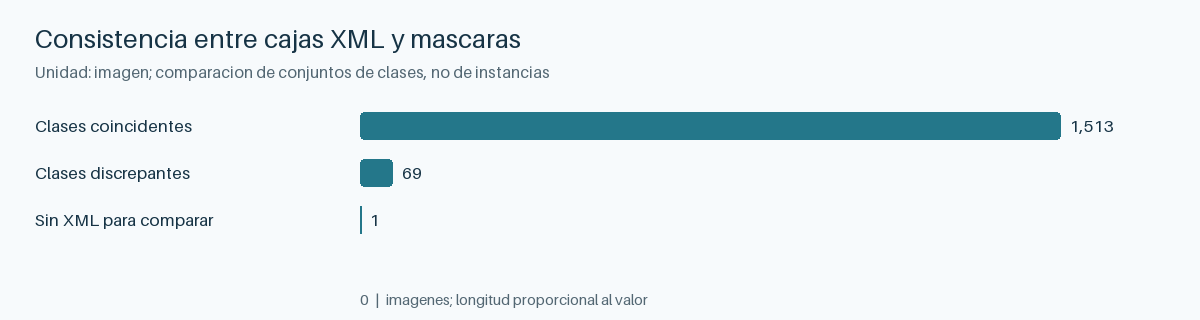

Incidencias adicionales: [{'id': 'image_1018', 'issue': 'missing_xml', 'detail': 'bboxes\\annotations\\image_1018.xml'}]


In [2]:
# Cobertura: cuántas fotografías tienen una máscara técnicamente utilizable.
# Las 102 sin máscara NO son imágenes negativas confirmadas.
show(bars(['Pares técnicamente válidos','Imágenes sin máscara'],
          [len(valid), summary['status_counts'].get('missing_mask',0)],
          '¿Con cuántos pares podemos comenzar?',
          'Conteo de archivos; aprobación visual y semántica todavía pendiente'), '01_cobertura')
# trainval es la UNION de train y val: sumarlo de nuevo duplicaría el conteo.
show(bars(['Train original','Validación original'],
          [summary['original_split_counts']['train'],summary['original_split_counts']['val']],
          'Particiones heredadas del dataset',
          'Se describen; todavía no se validan como independientes'), '02_splits')
print('Solapamiento de IDs train/val:', len(summary['original_split_overlap']))
print('IDs de splits sin par:', summary['split_ids_missing_image_or_mask'])
disagreements = len(summary['xml_mask_class_set_disagreements'])
missing_xml = sum(i['issue'] == 'missing_xml' for i in summary['issues'])
# Comparamos conjuntos de nombres de clase. Una discrepancia no demuestra por sí
# sola que la silueta sea incorrecta, ni que ambos anotadores vean el mismo objeto.
show(bars(['Clases coincidentes','Clases discrepantes','Sin XML para comparar'],
          [len(valid)-missing_xml-disagreements,disagreements,missing_xml],
          'Consistencia entre cajas XML y máscaras',
          'Unidad: imagen; comparación de conjuntos de clases, no de instancias'), '03_consistencia')
print('Incidencias adicionales:', summary['issues'])


**Decisión derivada:** usar solo pares técnicamente válidos como candidatos a revisión;
conservar trazabilidad de excluidos. **Impacto en arquitectura:** comenzar con salida binaria;
una salida por clase requiere depurar semántica. **Riesgo:** consistencia de archivos no implica
verdad terreno correcta. La discrepancia entre conjuntos de clases es un indicador para revisión,
no una prueba de que toda la máscara esté mal.


## 2. Tamaño de imagen y proporción de etiqueta

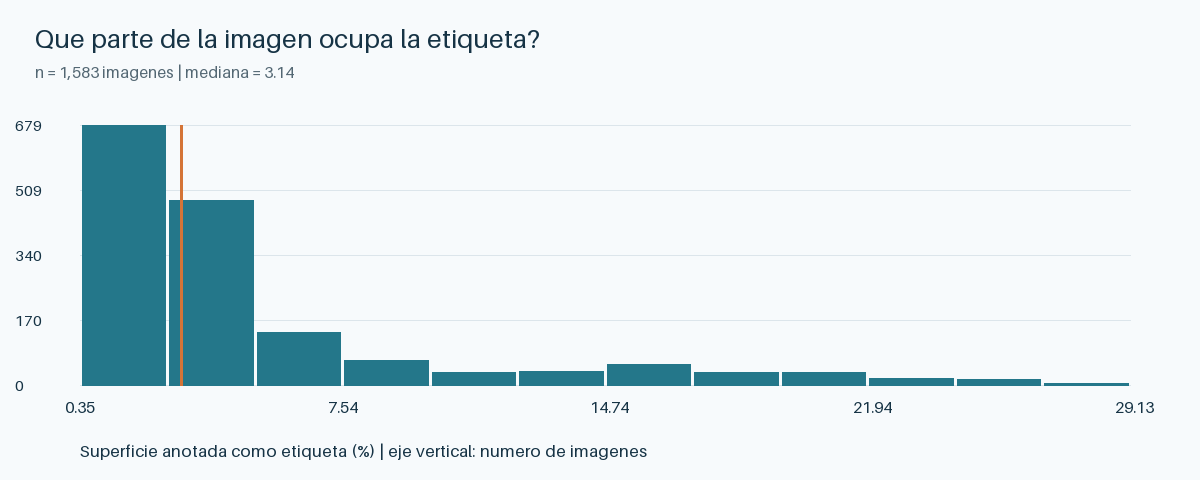

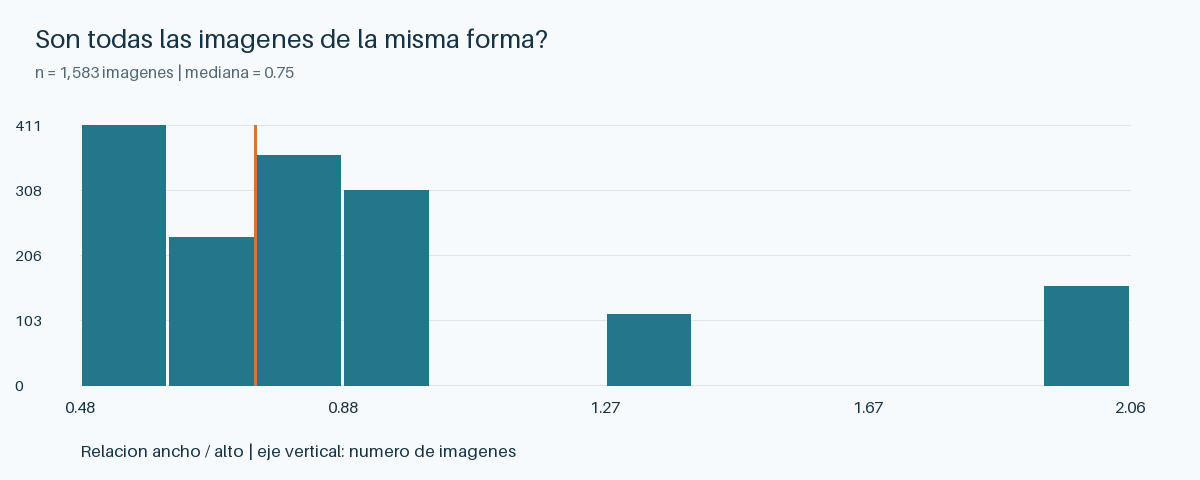

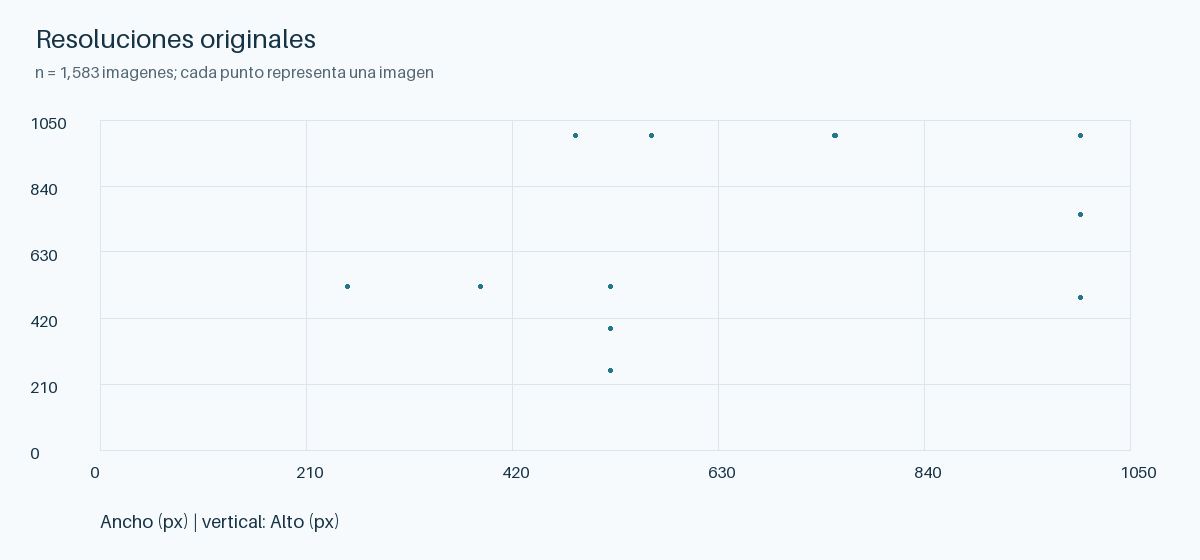

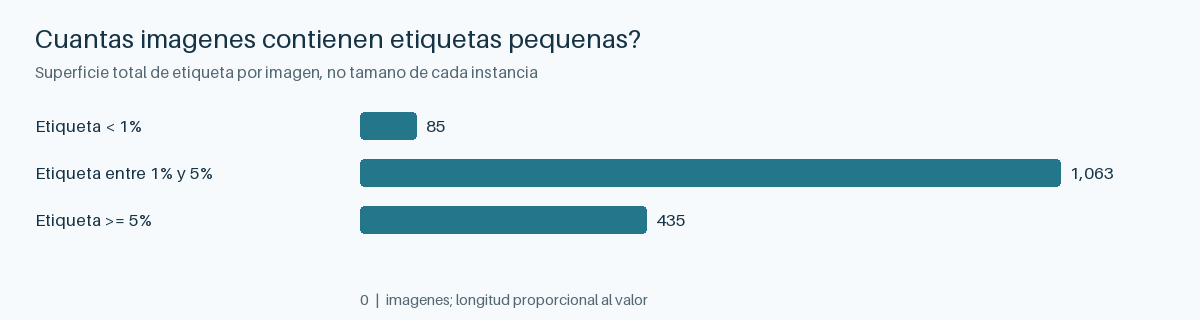

In [3]:
# Ancho y alto están en píxeles originales. La relación ancho/alto informa
# si una imagen es vertical (<1), cuadrada (=1) u horizontal (>1).
widths = np.array([int(r['width']) for r in valid])
heights = np.array([int(r['height']) for r in valid])
# Fracción de etiqueta = píxeles de etiqueta / píxeles totales de ESA imagen.
# No es lo mismo que la frecuencia de clases ni el número de etiquetas.
fractions = np.array([float(r['foreground_fraction']) for r in valid])
# El histograma muestra distribución; la línea naranja es la mediana:
# la mitad de las imágenes queda a cada lado. El tamaño de las barras cuenta imágenes.
show(histogram(100*fractions,'¿Qué parte de la imagen ocupa la etiqueta?',
               'Superficie anotada como etiqueta (%)'), '04_superficie')
show(histogram(widths/heights,'¿Son todas las imágenes de la misma forma?',
               'Relación ancho / alto'), '05_aspecto')
# El diagrama de dispersión hace visible la variedad de resoluciones.
# Los puntos superpuestos pueden representar varias imágenes del mismo tamaño.
show(scatter(widths, heights, 'Resoluciones originales', 'Ancho (px)','Alto (px)'), '06_resoluciones')
# Estos tres intervalos NO se solapan: evitan contar una imagen dos veces.
show(bars(['Etiqueta < 1%','Etiqueta entre 1% y 5%','Etiqueta >= 5%'],
          [int((fractions<.01).sum()),int(((fractions>=.01)&(fractions<.05)).sum()),int((fractions>=.05).sum())],
          '¿Cuántas imágenes contienen etiquetas pequeñas?',
          'Superficie total de etiqueta por imagen, no tamaño de cada instancia'), '07_objetos_pequenos')


**Decisión derivada:** elegir resolución después de comprobar cuánto se reducen las etiquetas
pequeñas; preservar relación de aspecto con padding como opción a evaluar. No fijar aún 224×224
por costumbre. **Impacto en arquitectura:** preservar información espacial y evaluar codificadores
que no eliminen objetos pequeños. **Riesgo:** estiramiento o reducción agresiva puede deformar
o borrar etiquetas. Las máscaras deben redimensionarse con vecino más cercano.


## 3. Desbalance a nivel de píxel y presencia de clases originales

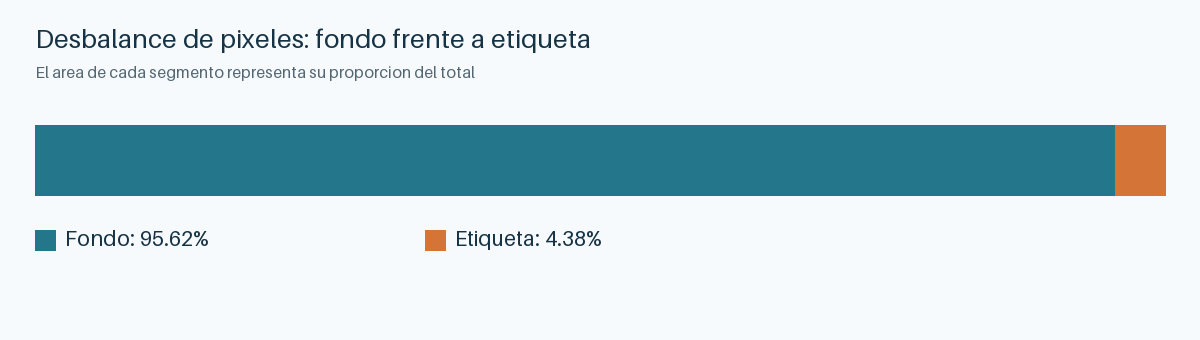

Razón fondo/etiqueta: 21.82
Exactitud global de predecir TODO fondo: 95.6187%
Referencia trivial de contexto, no uno de los tres modelos de Deep Learning.


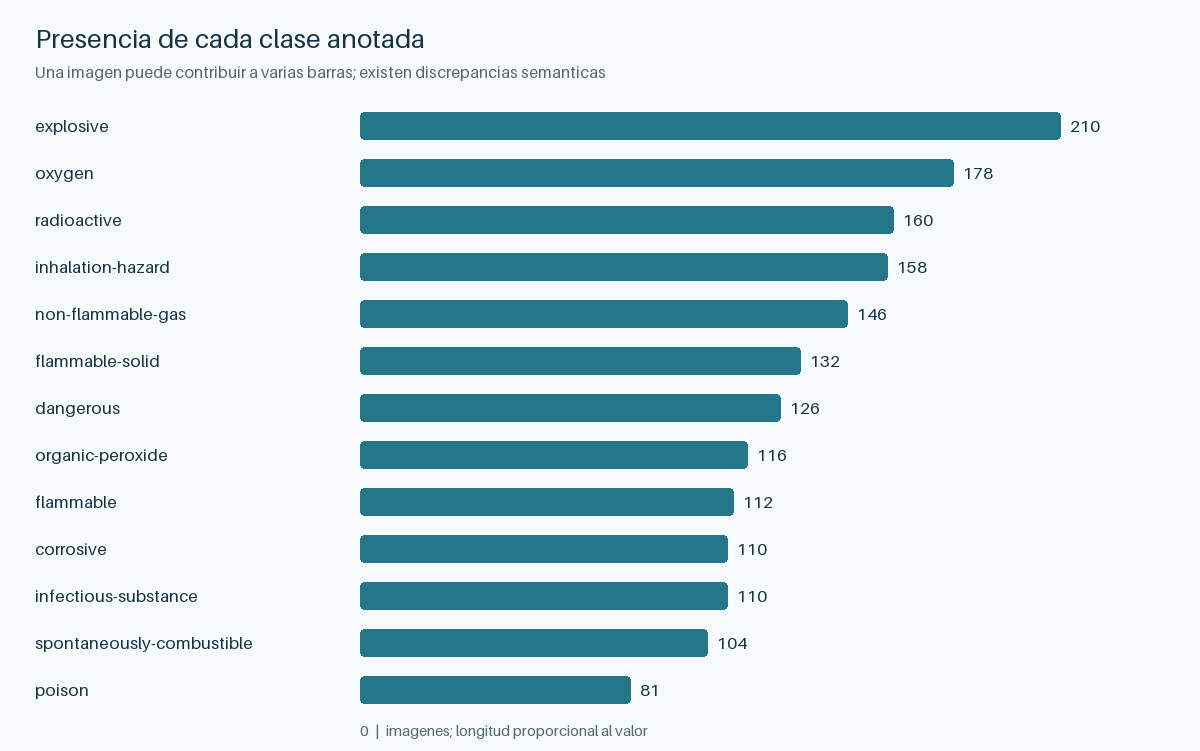

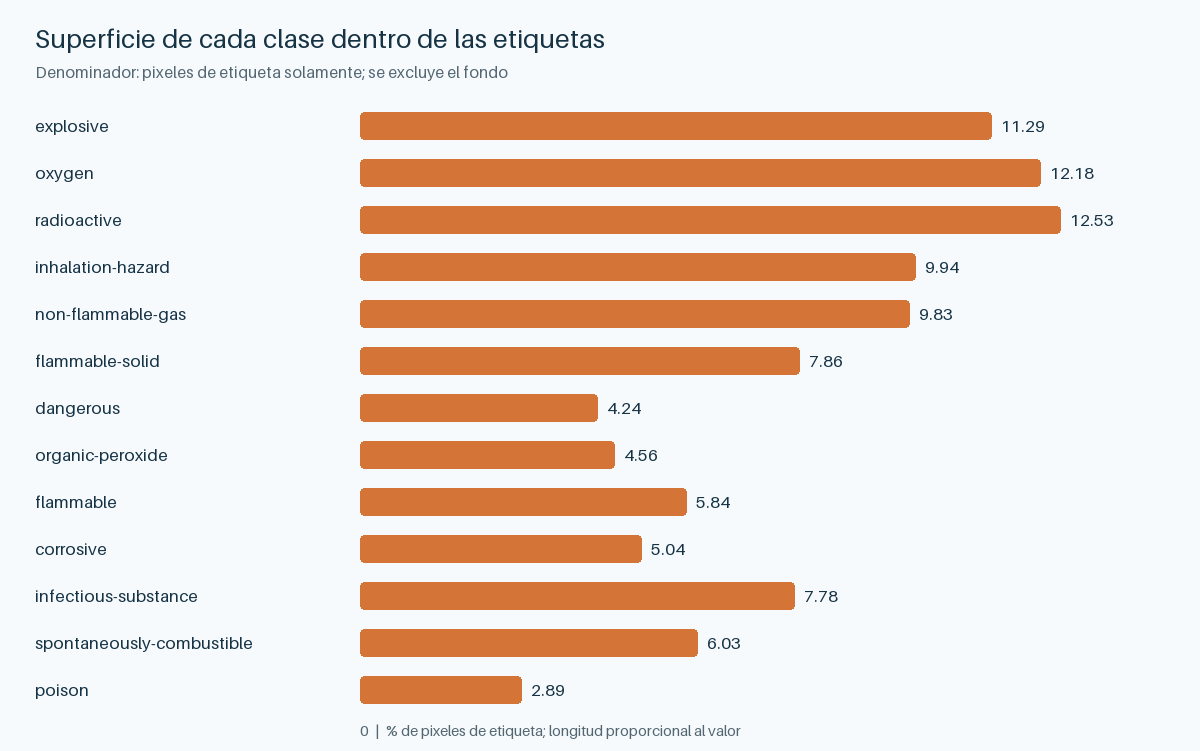

In [4]:
# Aquí agregamos PÍXELES: las imágenes grandes aportan más que las pequeñas.
# Por eso este porcentaje global difiere de la media de fracciones por imagen.
pixels = summary['pixel_counts_valid_pairs']
total = sum(pixels.values()); background = pixels['background']
foreground = total - background
show(composition(['Fondo','Etiqueta'], [background,foreground],
                 'Desbalance de píxeles: fondo frente a etiqueta',
                 'El área de cada segmento representa su proporción del total'), '08_balance_pixeles')
print(f'Razón fondo/etiqueta: {background/foreground:.2f}')
print(f'Exactitud global de predecir TODO fondo: {background/total:.4%}')
print('Referencia trivial de contexto, no uno de los tres modelos de Deep Learning.')
# Una imagen puede contener varias clases: sumar estas frecuencias NO da n imágenes.
# Son nombres de la fuente, no una ontología IMO ya validada.
classes = sorted(summary['class_image_counts_valid_pairs'],key=summary['class_image_counts_valid_pairs'].get,reverse=True)
show(bars(classes,[summary['class_image_counts_valid_pairs'][k] for k in classes],
          'Presencia de cada clase anotada',
          'Una imagen puede contribuir a varias barras; existen discrepancias semánticas'), '09_presencia_clases')
# Comparar esta figura con la anterior permite distinguir frecuencia de aparición
# y superficie: una clase puede aparecer mucho, pero ocupar pocos píxeles.
show(bars(classes,[100*pixels[k]/foreground for k in classes],
          'Superficie de cada clase dentro de las etiquetas',
          'Denominador: píxeles de etiqueta solamente; se excluye el fondo',
          unit='% de píxeles de etiqueta',color='#d47437'), '10_area_clases')


**Decisión derivada:** proponer Dice de etiqueta como métrica primaria y estudiar pérdidas
que consideren desbalance. **Impacto en arquitectura:** una salida binaria es suficiente para esta
primera pregunta. **Riesgo:** exactitud de píxel alta puede ocultar ausencia total de detección de
etiquetas. Las clases originales contienen discrepancias y sus frecuencias son anotaciones observadas,
no clases IMO validadas.


## 4. Duplicados y evaluación independiente

In [5]:
print('Grupos de duplicados exactos:', len(summary['exact_duplicate_groups']))
print('Grupos exactos entre train/val originales:',len(summary['exact_duplicates_cross_original_splits']))
print('LIMITES:')
for limit in summary['limits']:print('-',limit)


Grupos de duplicados exactos: 0
Grupos exactos entre train/val originales: 0
LIMITES:
- Casi duplicados y agrupacion por escena pendientes
- ok indica integridad tecnica, no aprobacion semantica o espacial
- No hay split final ni test congelado
- EDA exploratorio del corpus; las decisiones futuras se ajustaran en train
- La comparacion XML-mascara es por conjuntos de clases, no por instancia


**Decisión derivada:** investigar casi duplicados y grupos de escena antes de crear train/val/test.
**Impacto en arquitectura:** comparar todos los modelos con el mismo protocolo, sin adaptar su
capacidad al test. **Riesgo:** imágenes diferentes en bytes pueden mostrar la misma escena.
Ausencia de duplicados exactos no prueba independencia. No se calculan todavía medias de canal
para normalización: deben estimarse solo con el train definitivo.


## 5. Inspección visual reproducible — 30 imágenes

IDs muestreados: ['image_1412', 'image_0106', 'image_0193', 'image_0290', 'image_0515', 'image_0017', 'image_1344', 'image_0710', 'image_0889', 'image_0610', 'image_1461', 'image_0025', 'image_0054', 'image_0246', 'image_0473', 'image_0597', 'image_0300', 'image_0375', 'image_0677', 'image_1260', 'image_0741', 'image_1481', 'image_0006', 'image_0530', 'image_1558', 'image_1513', 'image_1106', 'image_0013', 'image_0170', 'image_1251']
panel_01.jpg


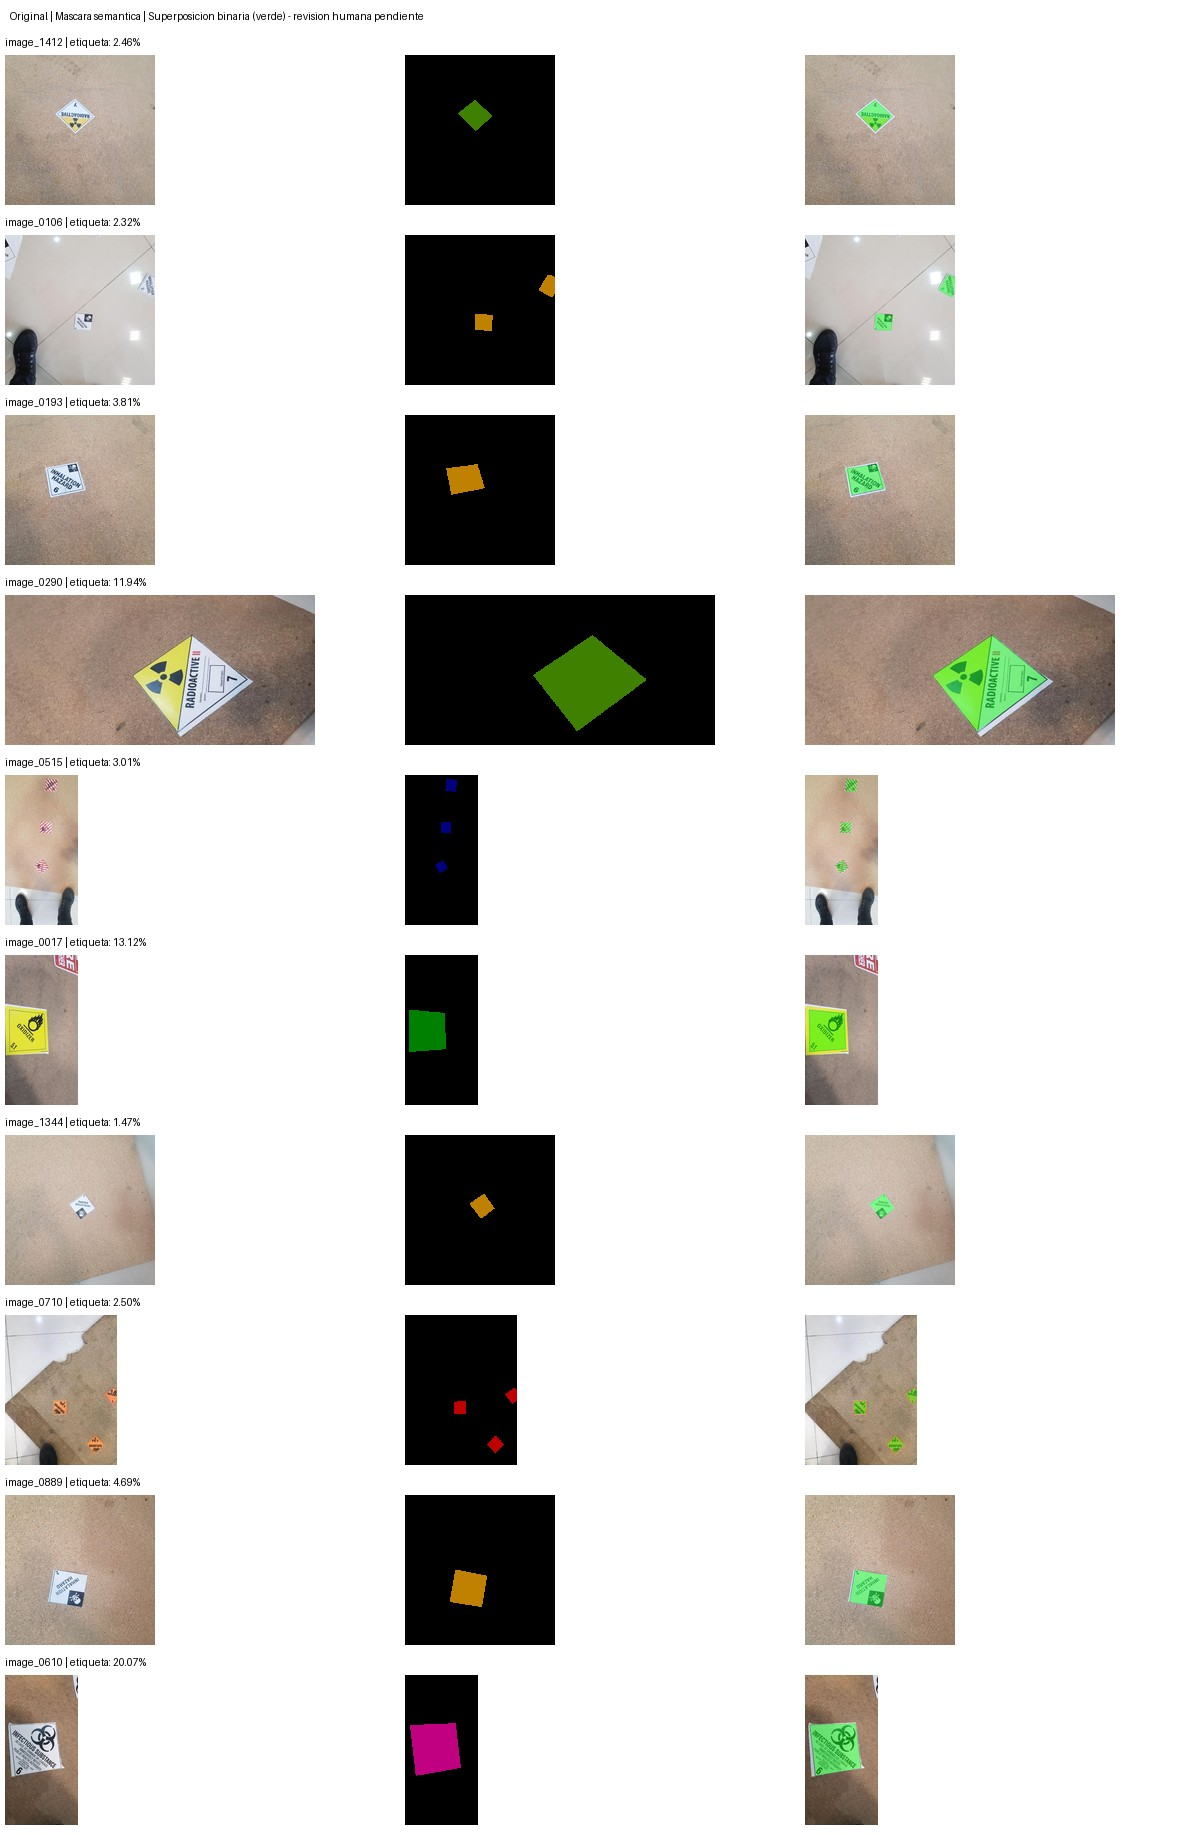

panel_02.jpg


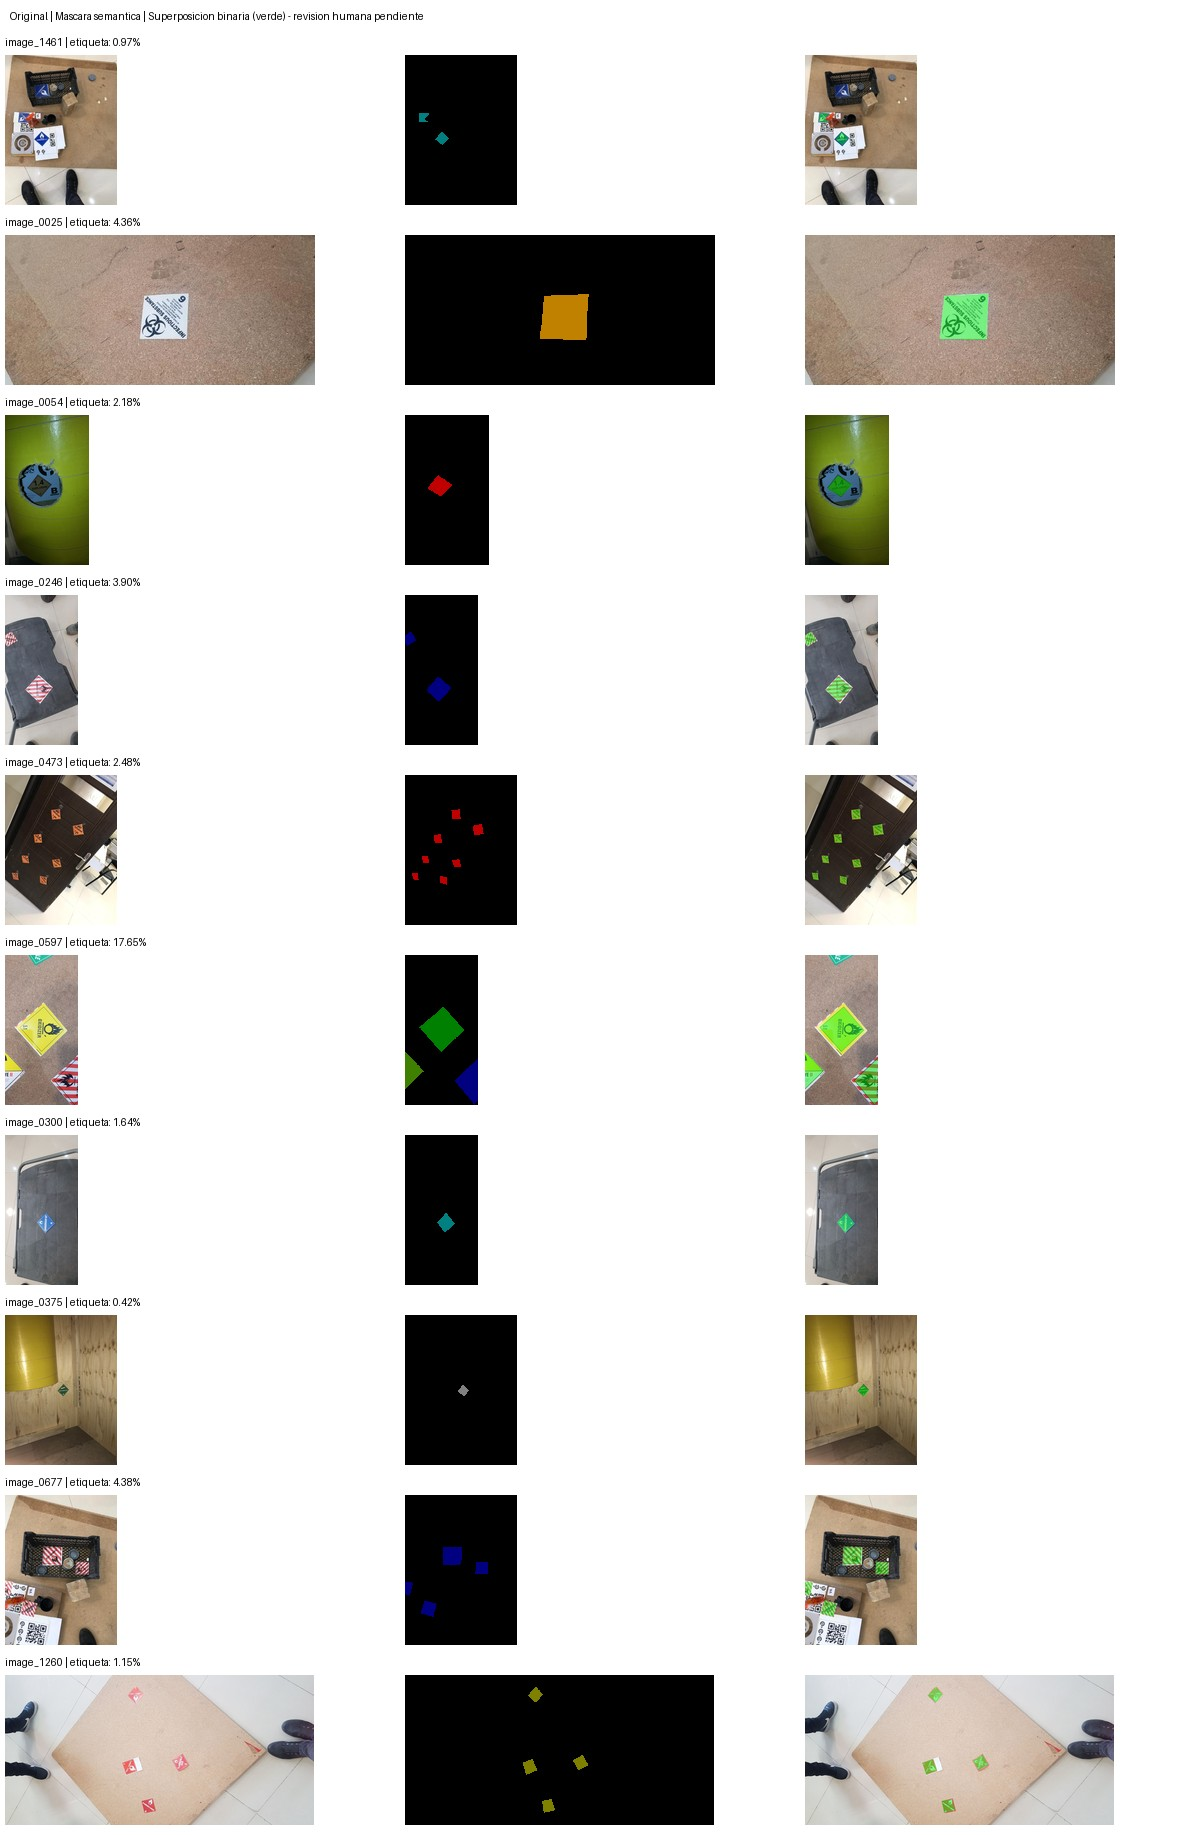

panel_03.jpg


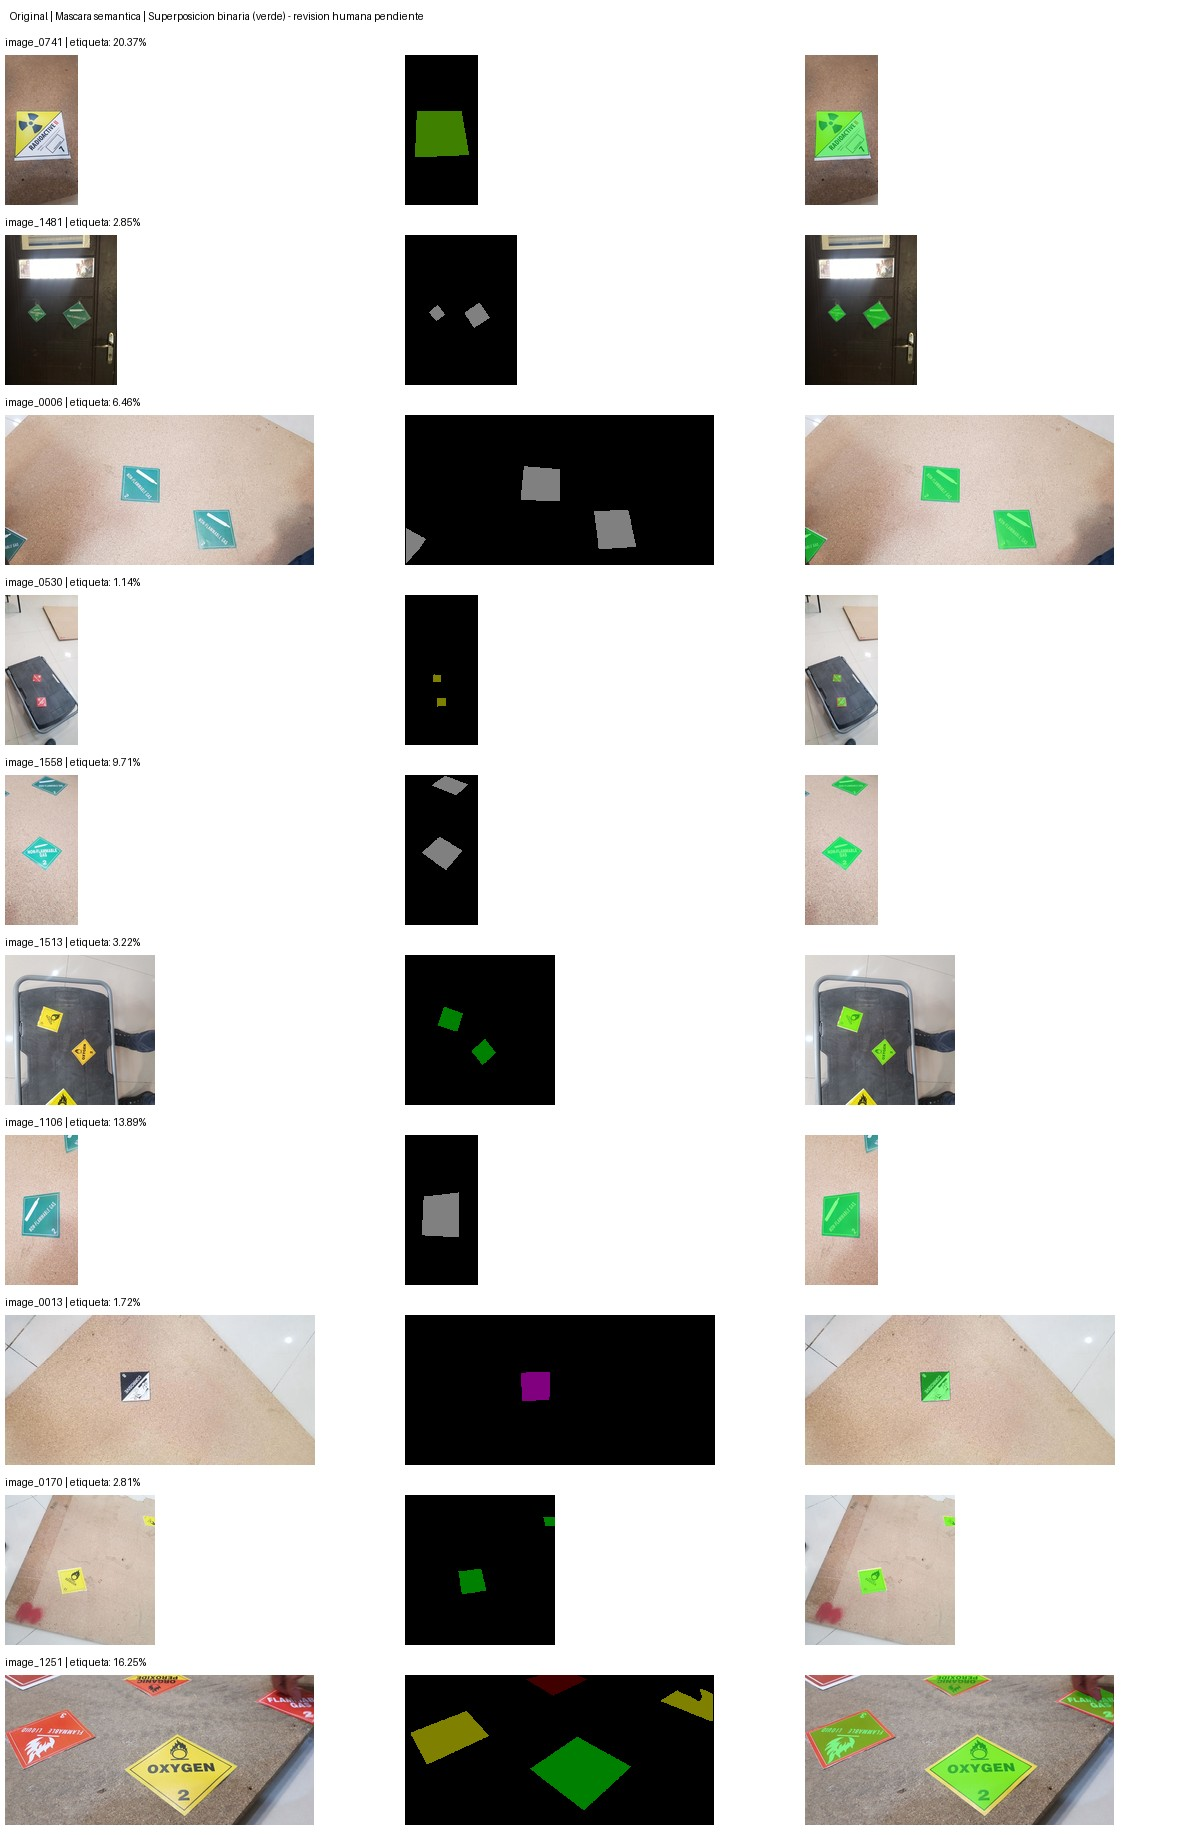

In [6]:
print('IDs muestreados:', summary['visual_sample_ids'])
for panel in sorted(out.glob('panel_*.jpg')):
    print(panel.name)
    with Image.open(panel) as img: display(img.copy())


**Observación exploratoria del asistente:** en los tres paneles se ven rótulos en tablas,
suelo, maletas y otros objetos de interior. Hay etiquetas pequeñas, parcialmente fuera de cuadro
y ocluidas. Las superposiciones permiten reconocer muchas de sus superficies, pero las miniaturas
no bastan para certificar bordes finos ni exhaustividad. `image_1461` y `image_0677` merecen
revisión ampliada por objetos superpuestos; `image_1251`, por recorte y oclusión.

**Decisión derivada:** revisar casos complejos a resolución original y documentar reglas para
oclusiones y bordes. **Impacto en arquitectura:** no confundir una tarea de máscaras binarias
con clasificación de peligros. **Riesgo:** fondos repetidos pueden crear atajos; el rendimiento
en este corpus no demuestra generalización portuaria. No existe aún validación de un anotador humano.


## 6. Segunda etapa: similitud visual y agrupamiento

**Pregunta:** ¿hay fotografías iguales o muy parecidas que puedan inflar la evaluación?
Comparamos tres cosas distintas: bytes del JPEG, píxeles RGB decodificados y apariencia
resumida con dHash/aHash. La primera revisión solo comprobó bytes; una imagen puede
reaparecer con otros metadatos o compresión.

Los umbrales exploratorios (distancia máxima 6 en cada hash de 64 bits) se guardaron en
`config/revision_voc.json` antes de la búsqueda. No son umbrales de similitud validados.
Se examinan todos los pares de los 1.685 JPG, incluyendo los que no tienen máscara.


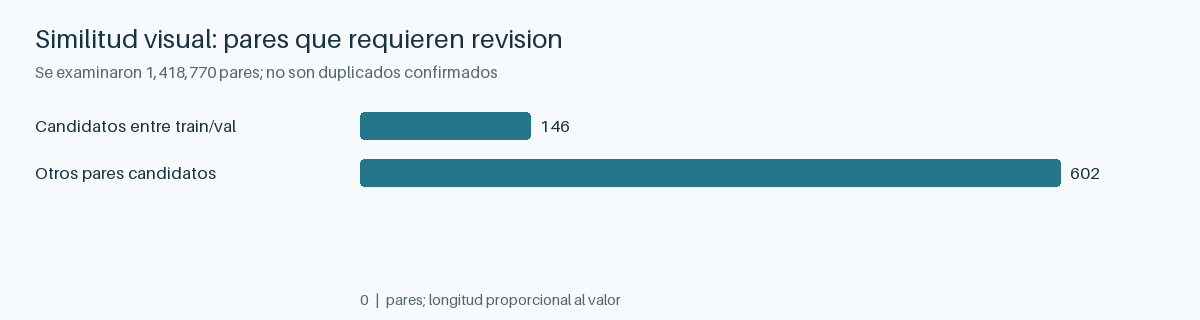

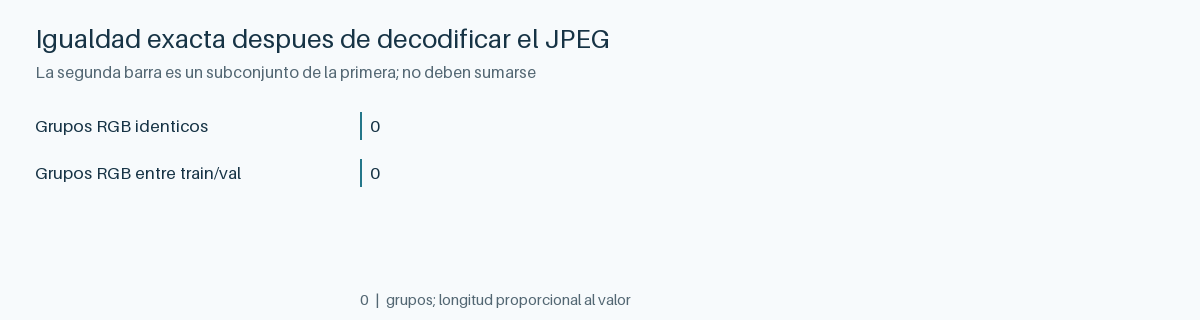

0 bits diferentes = misma firma perceptual, NO necesariamente mismos píxeles.
Confirmación de igualdad RGB = hash de dimensiones y todos los píxeles decodificados.


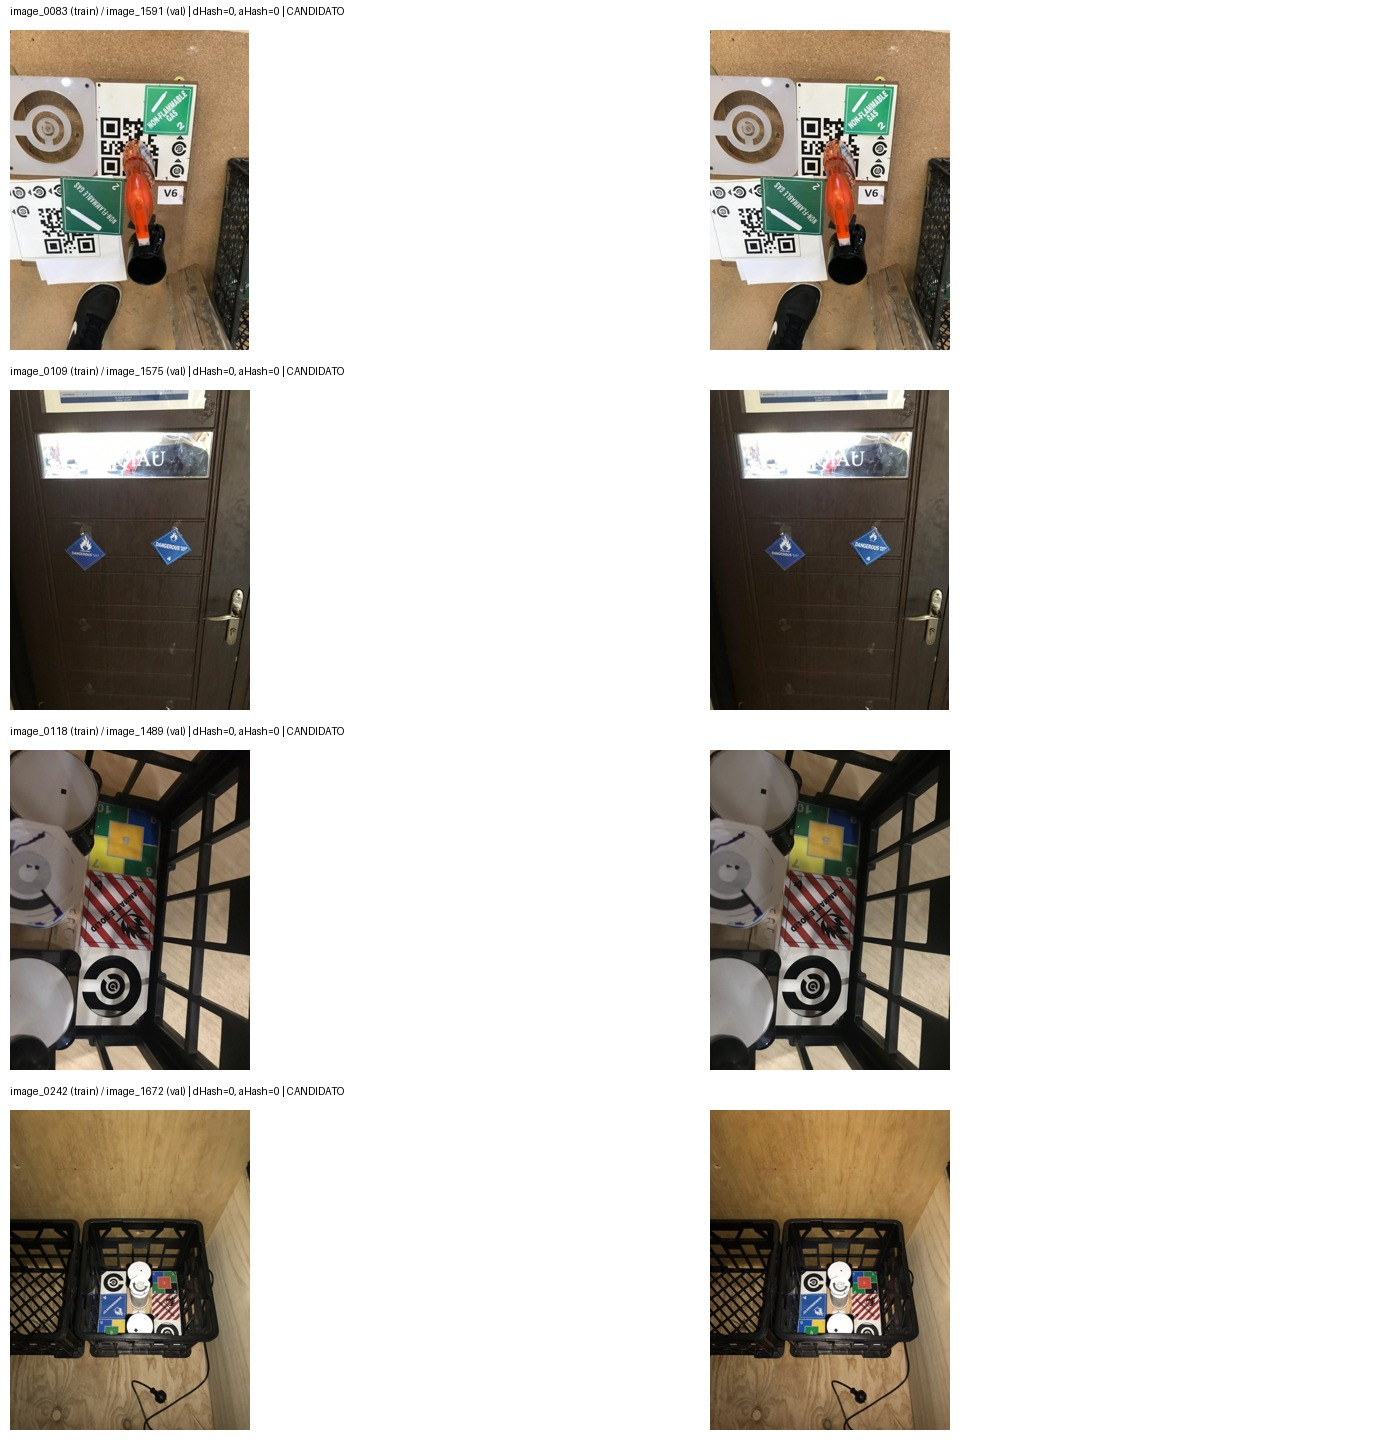

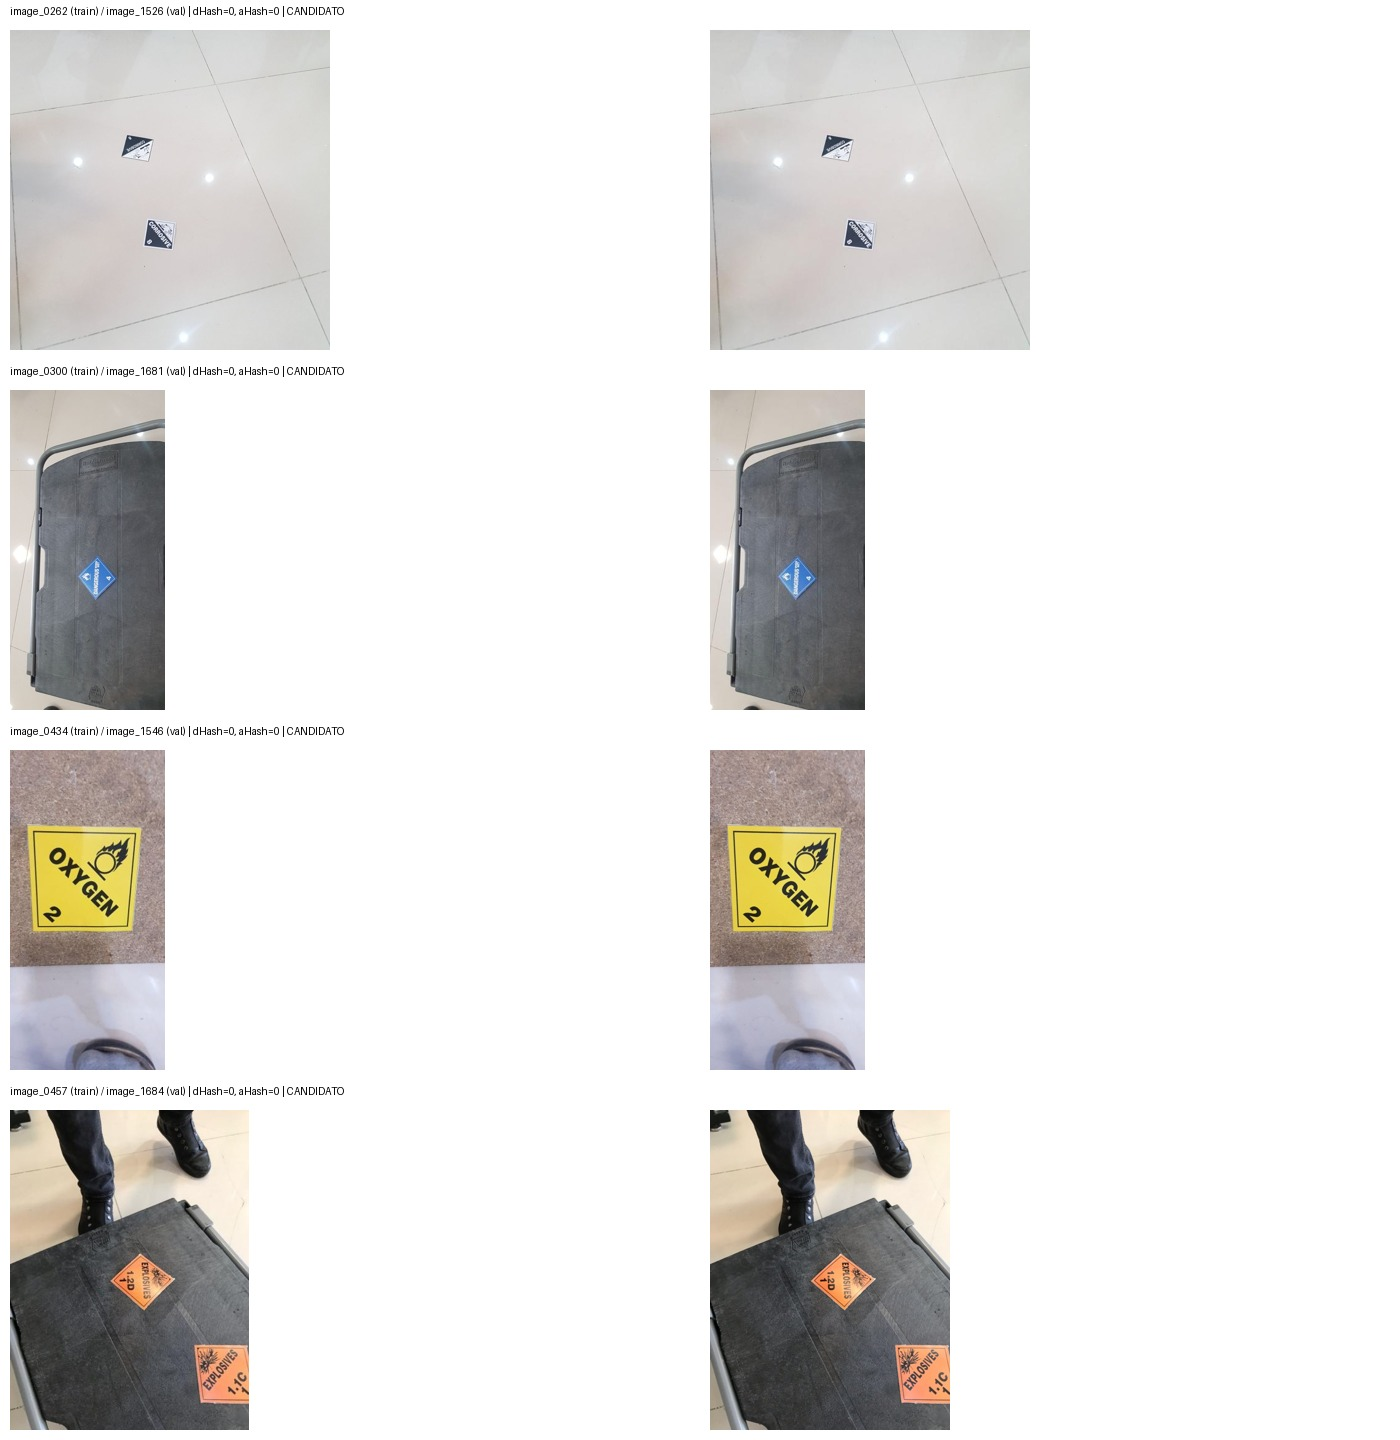

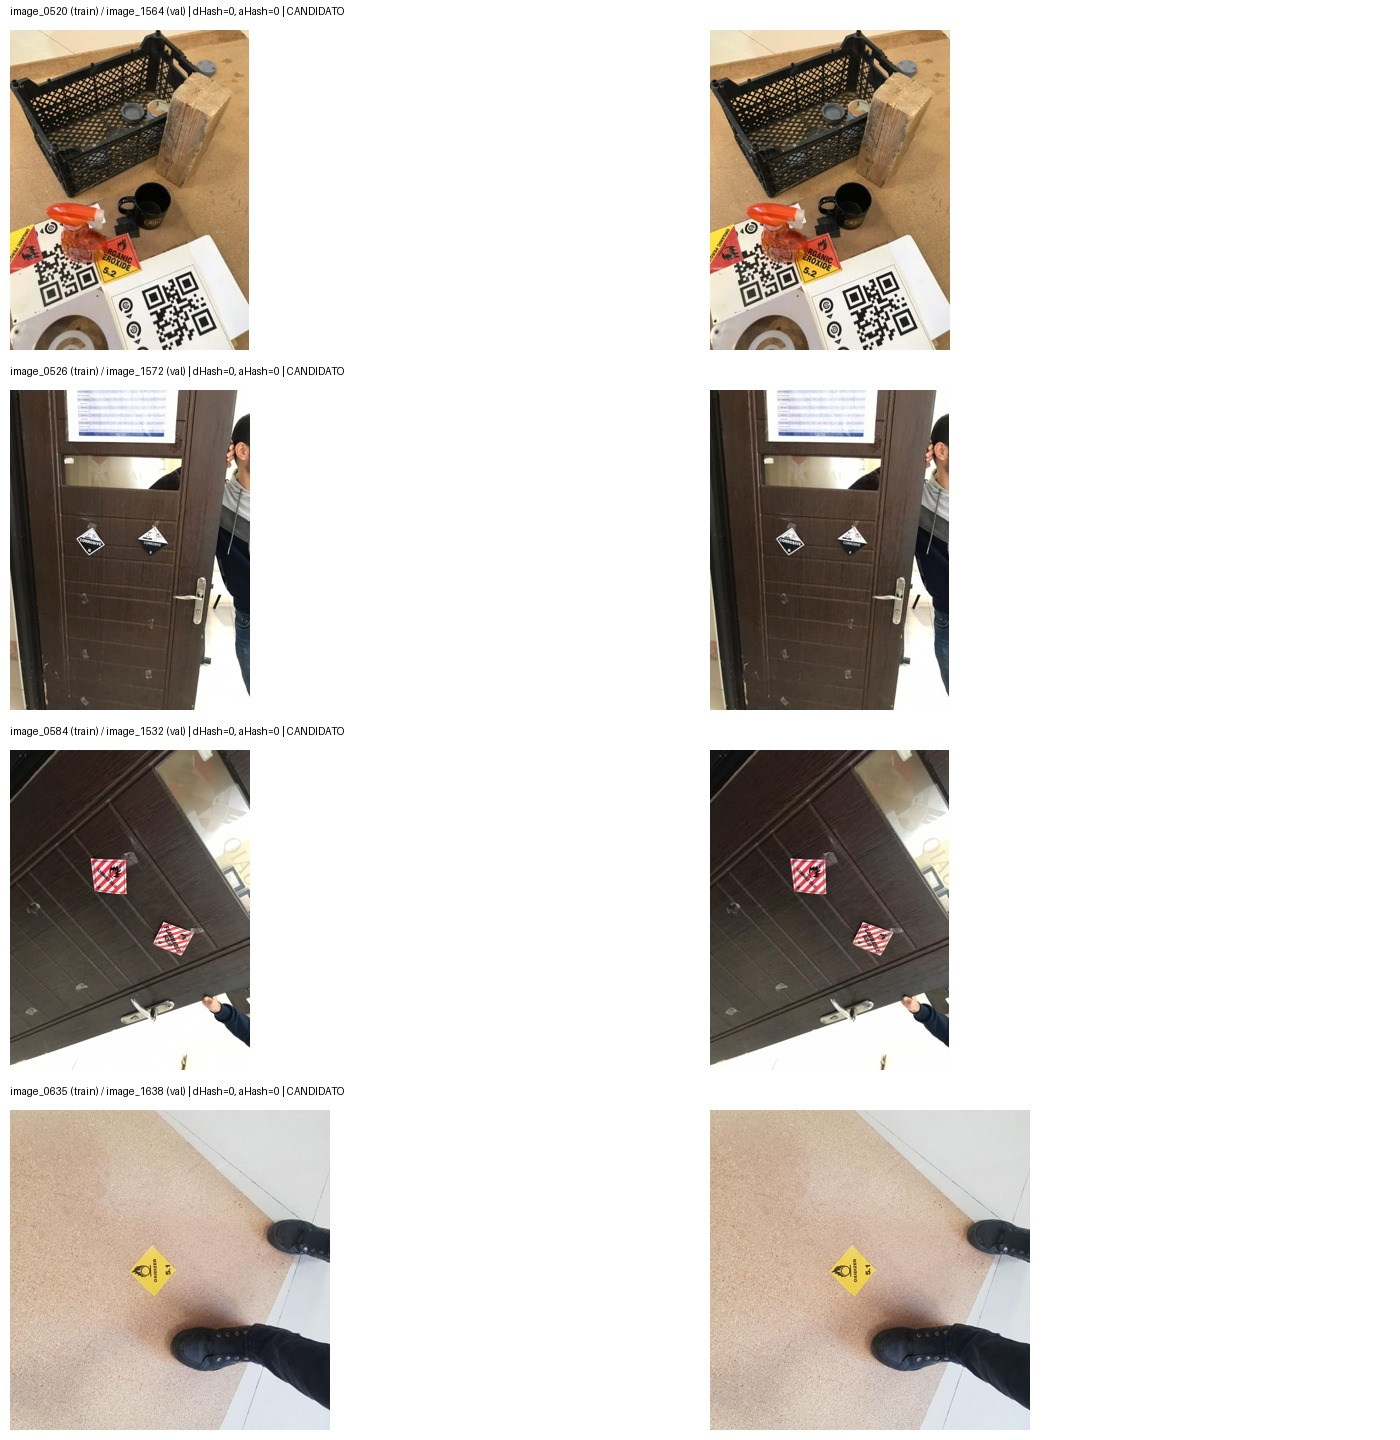

In [7]:
review_dir = project / 'resultados/revision_voc'
review = json.loads((review_dir / 'resumen.json').read_text(encoding='utf-8'))
with (review_dir / 'caracteristicas_imagen.csv').open(encoding='utf-8-sig') as f:
    features = list(csv.DictReader(f))
with (review_dir / 'candidatos_similares.csv').open(encoding='utf-8-sig') as f:
    candidates = list(csv.DictReader(f))

# Un PAR es una comparación entre dos archivos. Un GRUPO puede contener más de dos.
# No sumamos pares de similitud a grupos de igualdad: son unidades distintas.
cross = review['candidate_pairs_cross_train_val']
show(bars(['Candidatos entre train/val','Otros pares candidatos'],
          [cross,review['candidate_pairs']-cross],
          'Similitud visual: pares que requieren revisión',
          f"Se examinaron {review['all_pairs_examined']:,} pares; no son duplicados confirmados",unit='pares'), '11_similitud')
pixel_groups = review['identical_rgb_pixel_groups']
pixel_cross = review['identical_rgb_pixel_groups_cross_train_val']
show(bars(['Grupos RGB idénticos','Grupos RGB entre train/val'],
          [len(pixel_groups),len(pixel_cross)],
          'Igualdad exacta después de decodificar el JPEG',
          'La segunda barra es un subconjunto de la primera; no deben sumarse',unit='grupos'), '12_igualdad_rgb')
print('0 bits diferentes = misma firma perceptual, NO necesariamente mismos píxeles.')
print('Confirmación de igualdad RGB = hash de dimensiones y todos los píxeles decodificados.')
for panel in sorted(review_dir.glob('pares_*.jpg')):
    with Image.open(panel) as im: display(im.copy())


**Decisión derivada:** no usar las particiones originales para reportar generalización
sin resolver las coincidencias. Los pares más similares mostrados presentan escenas visualmente
repetidas entre train y val. **Impacto en modelos:** una comparación justa requiere grupos
compartidos entre los tres modelos, nunca copias de una misma escena a ambos lados.
**Riesgo:** los hashes perceptuales pueden fallar con recortes y rotaciones o confundir fondos
parecidos. No eliminar candidatos automáticamente ni llamar a cada coincidencia una escena.


## 7. Procedencia interna e iluminación

El XML conserva una carpeta de origen (`folder`). Es una pista de colección, no una
identificación confirmada de persona, cámara o escena. Puede ayudar a detectar un
muestreo desigual, pero no basta para resolver las fugas: imágenes parecidas pueden
figurar bajo carpetas distintas.


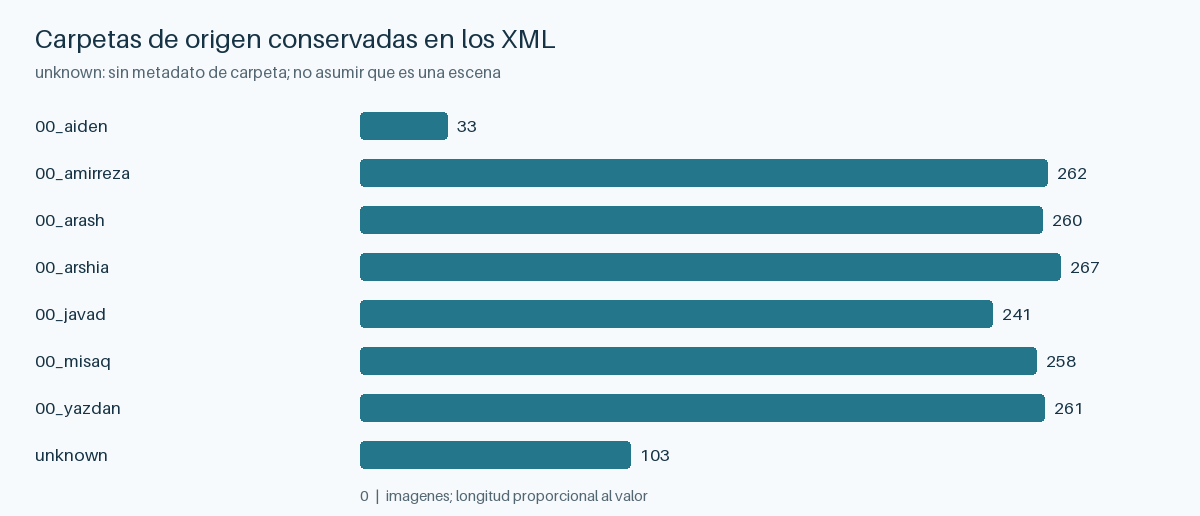

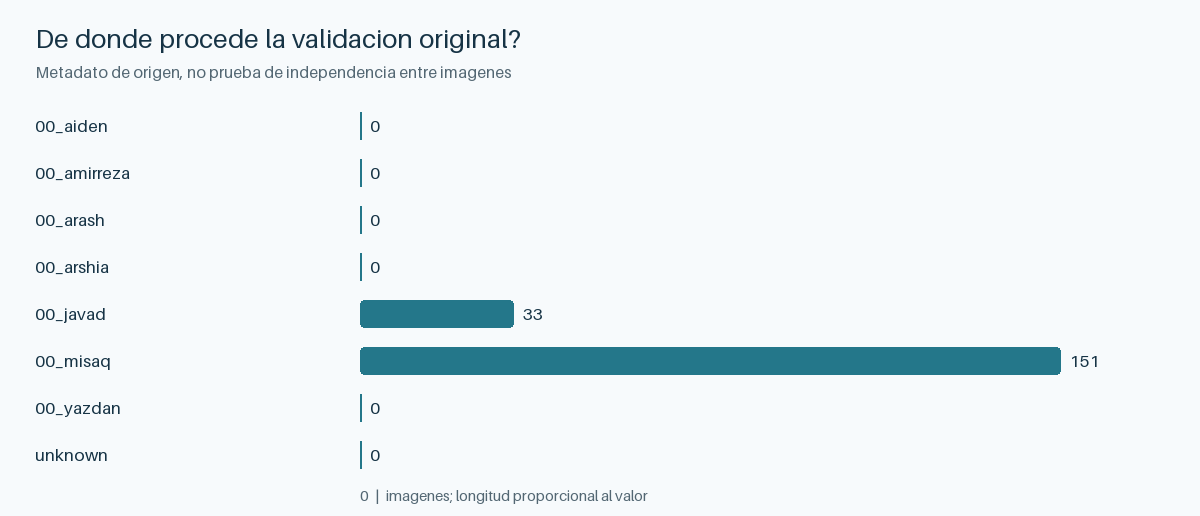

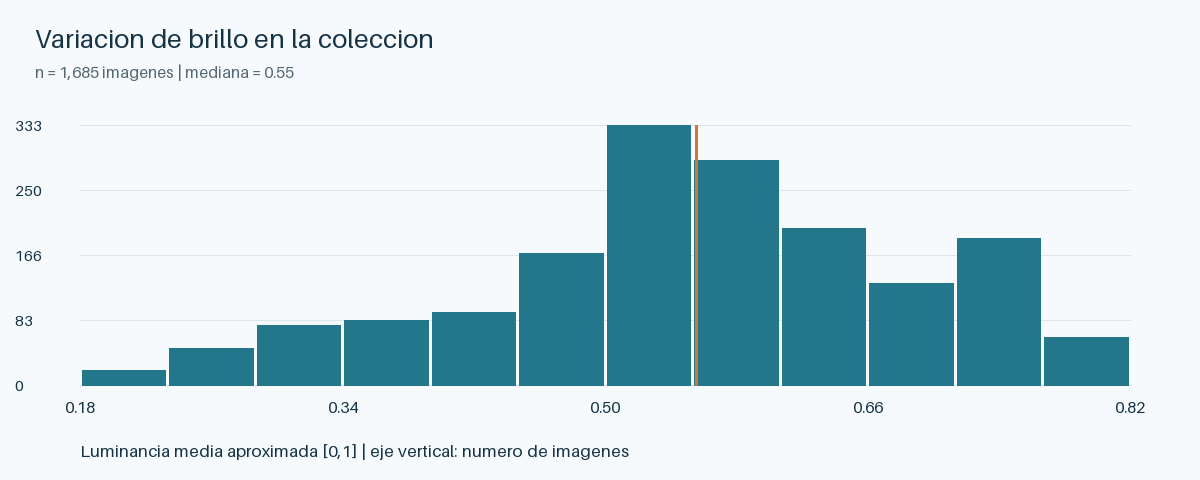

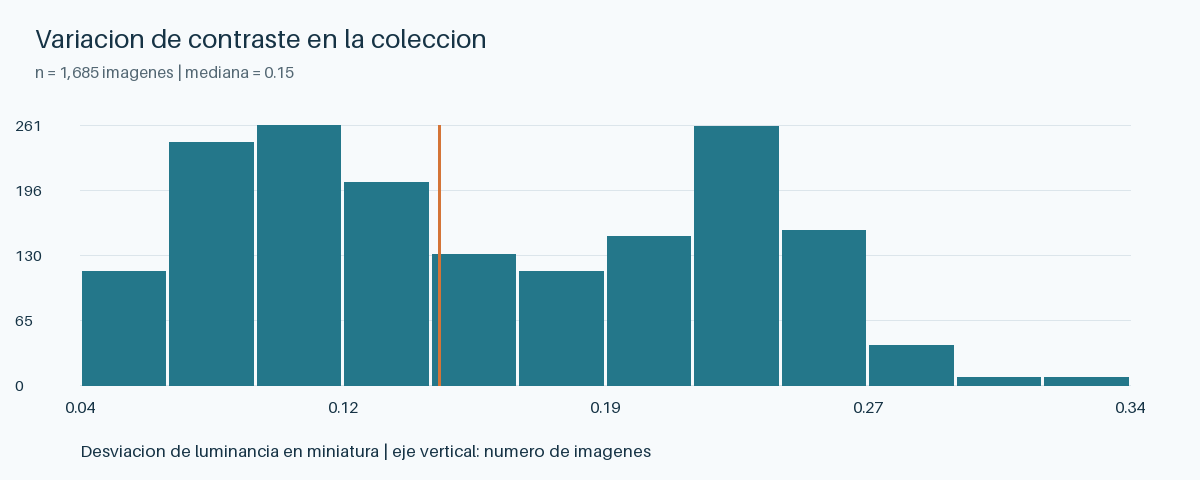

In [8]:
groups = review['source_folders']
# Mostrar presencia por carpeta permite ver qué lotes dominan la colección.
show(bars([g['source_folder_xml'] for g in groups],[g['images'] for g in groups],
          'Carpetas de origen conservadas en los XML',
          'unknown: sin metadato de carpeta; no asumir que es una escena'), '13_origen')
# Solo dos carpetas pueden aportar la validación heredada: visualizarlo revela
# una concentración de origen que un simple 80/20 no describe.
show(bars([g['source_folder_xml'] for g in groups],[g['val'] for g in groups],
          '¿De dónde procede la validación original?',
          'Metadato de origen, no prueba de independencia entre imágenes'), '14_origen_validacion')

# Luminancia aproximada = 0.2126 R + 0.7152 G + 0.0722 B, con RGB en [0,1].
# Se mide en miniaturas 128x128 para EDA, sin linealizar sRGB: es un indicador
# de brillo visual, NO una medición fotométrica física ni estadística de train.
brightness = np.array([float(r['brightness_thumb']) for r in features])
# Contraste = desviación estándar espacial de esa luminancia por imagen.
contrast = np.array([float(r['contrast_thumb']) for r in features])
show(histogram(brightness,'Variación de brillo en la colección',
               'Luminancia media aproximada [0,1]'), '15_brillo')
show(histogram(contrast,'Variación de contraste en la colección',
               'Desviación de luminancia en miniatura'), '16_contraste')


**Decisión derivada:** conservar metadatos de origen y revisar grupos de similitud antes
de diseñar nuevos splits. Estudiar aumentos de iluminación solo en train, sin transformar
el valor de clase de la máscara. **Impacto en arquitectura:** separar robustez visual de
memorización del fondo. **Riesgo:** las estadísticas de esta colección completa no se deben
usar para normalizar el entrenamiento. Estas figuras no sustituyen una prueba formal de
desplazamiento entre futuras particiones.


## 8. Revisión ampliada de máscaras

Se generaron 12 paneles que conservan los píxeles originales: imagen, máscara y superposición.
Se priorizaron casos de oclusión y discrepancias de clase; esta muestra NO es aleatoria y
no sirve para estimar una tasa poblacional de error. Los colores originales se conservan:
la superposición verde solo facilita ver la geometría binaria.


Casos priorizados: ['image_0000', 'image_0011', 'image_0025', 'image_1461', 'image_0677', 'image_1251', 'image_0045', 'image_0053', 'image_0065', 'image_0139', 'image_0149', 'image_0192']
Caso: image_0000


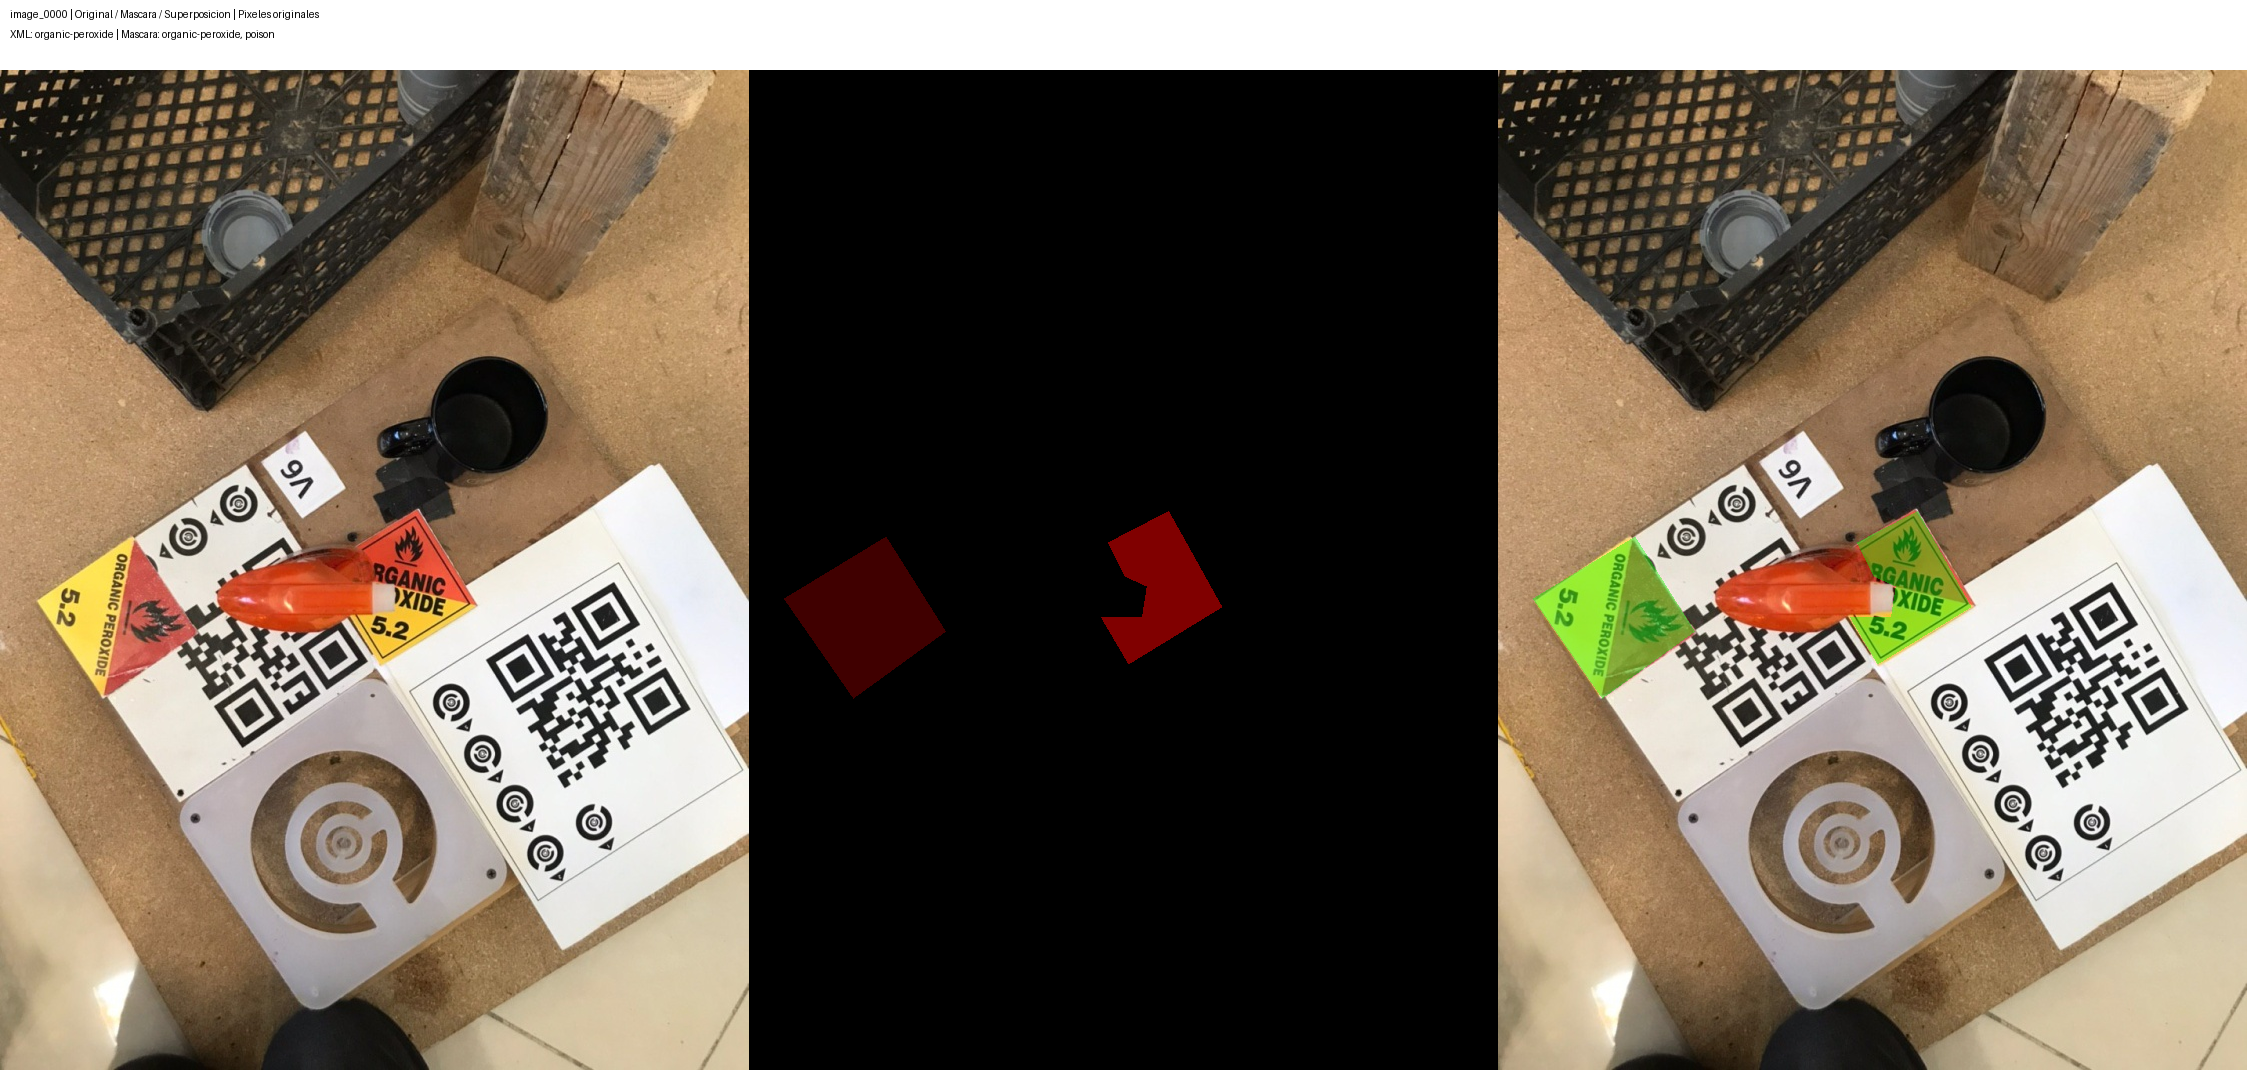

Caso: image_0011


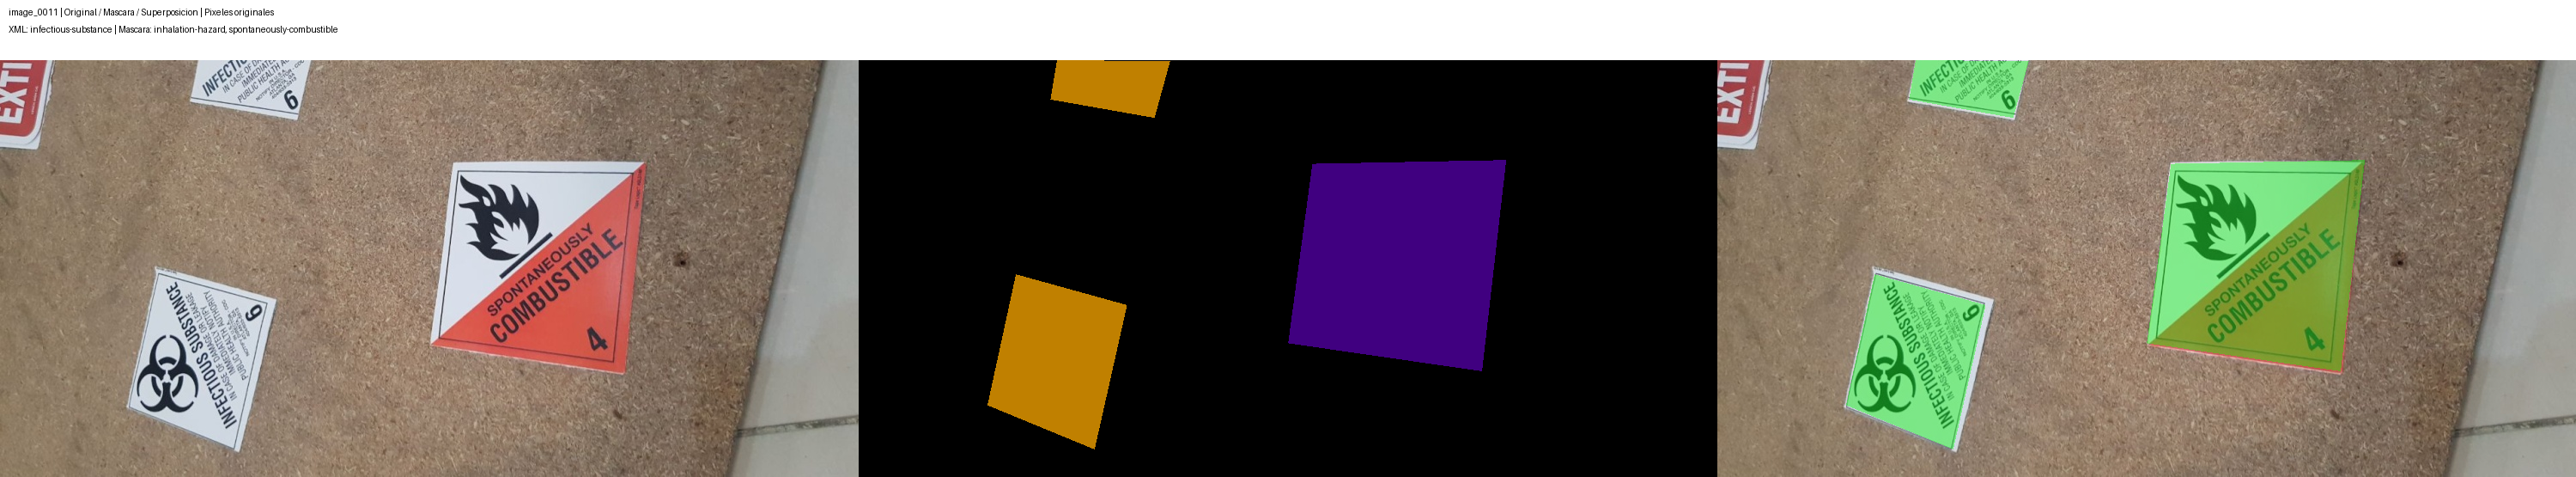

Caso: image_0025


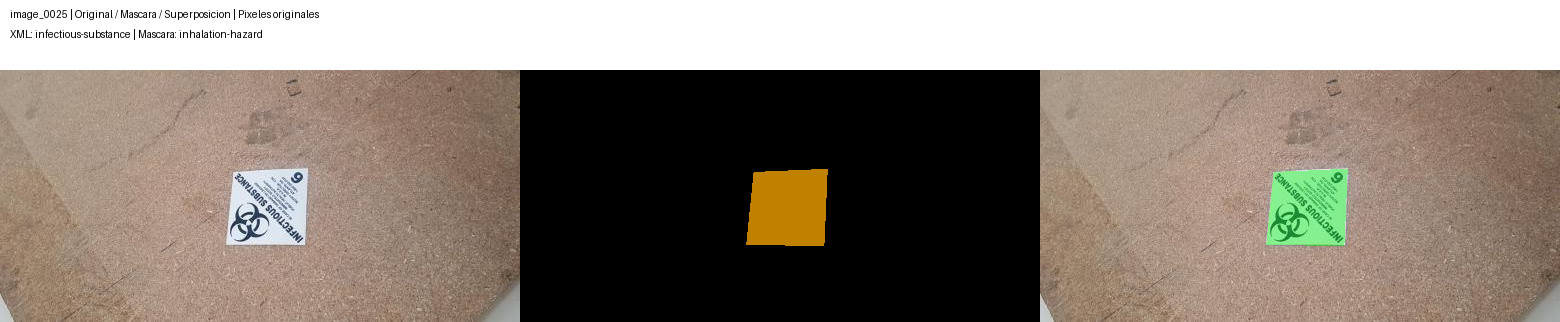

In [9]:
# Lista explícita para poder volver a encontrar cada caso y registrar decisiones.
print('Casos priorizados:', review['mask_review_ids'])
for image_id in ['image_0000','image_0011','image_0025']:
    print('Caso:',image_id)
    # El PNG guardado conserva la resolución original; el visor puede reducirlo.
    with Image.open(review_dir / f'mascara_{image_id}.png') as im: display(im.copy())


**Observaciones del asistente:** en image_0000 las dos etiquetas visibles dicen
organic peroxide, pero sus colores de máscara representan clases distintas. En image_0011
también aparece una etiqueta spontaneously combustible que el conjunto de clases XML no
recoge, además de etiquetas infectious substance con otro color semántico. Por tanto,
no se puede corregir todas las máscaras copiando sin más las clases de las cajas.
En image_0025 la silueta cubre el rótulo, pero el color semántico discrepa de su texto visible.
En la revisión ampliada de image_1461 se observa además un rótulo dentro de la cesta
que aparentemente no está cubierto por la máscara: es una alerta de cobertura incluso
para la tarea binaria, pendiente de adjudicación humana.

**Decisión derivada:** mantener anotaciones originales y registrar revisión por caso;
una discrepancia semántica no exige descartar automáticamente una silueta útil para binario.
**Impacto en arquitectura:** salida binaria sigue siendo una opción inicial razonable.
**Riesgo:** todavía falta revisión independiente, especialmente en bordes y oclusiones.


## 9. Siguiente bloque

1. Verificar procedencia, licencia y artículos que usaron este dataset.
2. Revisar candidatos de similitud y consolidar grupos; ampliar con regiones conectadas
   y pruebas de distribución una vez propuestas las particiones.
3. Resolver o documentar discrepancias; fijar reglas de elegibilidad y máscaras vacías.
4. Seleccionar tres arquitecturas respaldadas por literatura.
5. Registrar delta, unidad independiente, splits y protocolo; preparar el piloto.

**Estado:** primer bloque y búsqueda exploratoria de similitud ejecutados; no hay modelos, métricas de desempeño aprendidas,
particiones definitivas ni EDA exhaustivo. El notebook es reutilizable en el futuro Jupyter Book;
su integración y compilación todavía no se han hecho.
